Rows: 55 Columns: 16
-- Column specification --------------------------------------------------------
Delimiter: "\t"
chr  (2): sample_id, condition
dbl (14): size, richness, d1, shannon, d2, simpson, d3, d4, chao1, ace, gini...

i Use `spec()` to retrieve the full column specification for this data.
i Specify the column types or set `show_col_types = FALSE` to quiet this message.
Warning message:
"There was 1 warning in `mutate()`.
i In argument: `across(everything(), as.numeric)`.
Caused by warning:
! NAs introduced by coercion"


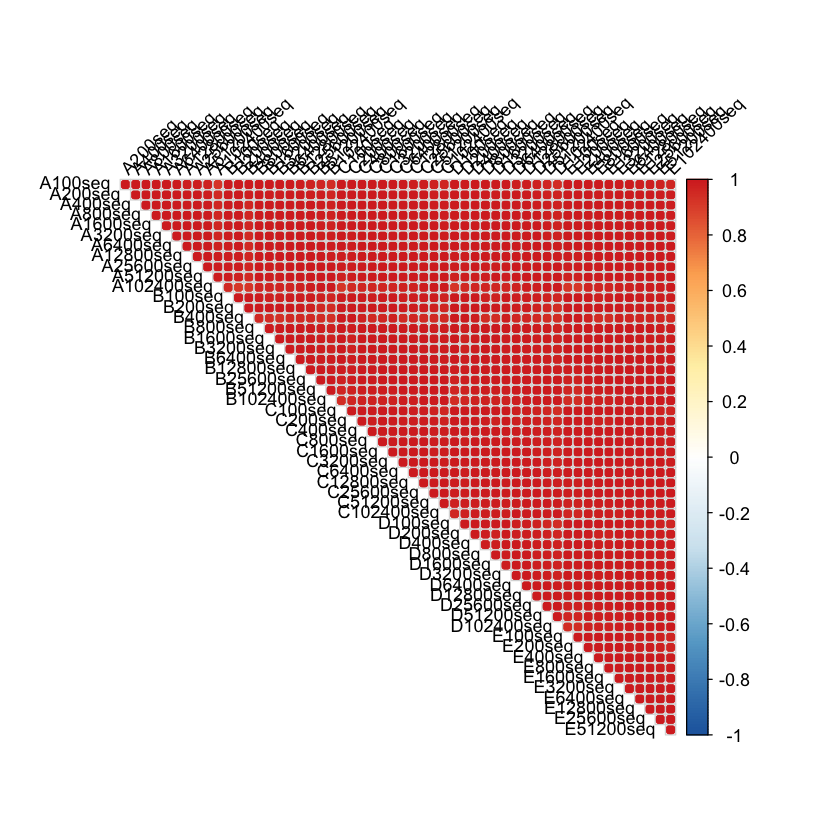

In [10]:

# CORRELOGRAMA DE PEARSON ENTRE MÉTRICAS DE DIVERSIDAD

library(tidyverse)
library(corrplot)

# 1. Leer matriz de diversidad
df <- read_tsv(
  "../results/diversity_matrix/diversity_matrix_A.tsv"
)

# 2. Convertir a matriz numérica
# Primera columna = métricas
mat <- df %>%
  column_to_rownames(var = names(df)[1]) %>%
  mutate(across(everything(), as.numeric)) %>%
  as.matrix()

# 3. Transponer para que las filas sean
# observaciones y las columnas sean métricas
mat_t <- t(mat)

# 4. Calcular correlación de Pearson
cor_pearson <- cor(
  mat_t,
  method = "pearson",
  use = "pairwise.complete.obs"
)

# 5. Graficar correlograma de círculos

corrplot(
  cor_pearson,
  method = "circle",
  type = "upper",
  order = "original",
  diag = FALSE,
  col.lim = c(-1, 1),
  col = colorRampPalette(
    c("#2166AC", "#67A9CF", "#D1E5F0",
      "white",
      "#FFF0B3", "#FDAE61", "#D73027")
  )(200),
  tl.col = "black",
  tl.srt = 45,
  tl.cex = 0.9,
  cl.cex = 0.9,
  addgrid.col = "grey85"
)

# 6. Guardar matriz de correlaciones
write.csv(
  cor_pearson,
  "../results/correlacion_pearson.csv"
)


In [11]:
round(quantile(vals, probs = c(0, 0.25, 0.5, 0.75, 1), na.rm = TRUE), 3)

0%   25%   50%   75%  100% 
0.919 0.986 0.993 0.998 1.000